<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FCoral-reef-health-monitoring/notebooks/C3_Day2c_More_Data_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Component 3 – Day 2c: More training data and SVM tuning
Supervisor feedback: accuracy is limited by the small amount of training data. Compared with Day 2b:
- samples per class per site increased from **300 to 1,000** (limited by the available pixels)
- **E4** = context features without the purity filter
- **SVM hyperparameter tuning** (C, gamma) with the same spatial folds
- `best_model.joblib` is replaced only if macro-F1 improves on Day 2b (0.565); otherwise the new model is saved as `best_model_v3.joblib`.

| Experiment | Composite | Label purity filter | Features |
|---|---|---|---|
| **E0** baseline | v1 (Day 1) | – | pixel (glint-corrected B2/B3/B4) |
| **E1** | v2 (cleaner) | – | pixel |
| **E2** | v2 | ≥ 0.75 | pixel |
| **E3** | v2 | ≥ 0.75 | pixel + neighbourhood (3×3, 5×5) |
| **E4** | v2 | – | pixel + neighbourhood (3×3, 5×5) |

Uses the Day 1 and Day 1b files in Drive (no Earth Engine login). Outputs: `coral_c3/results_v3/`.

## Part 0 – Setup

In [1]:
!pip install -q rasterio xgboost
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, json, time, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio, joblib
from scipy.ndimage import uniform_filter

BASE = '/content/drive/MyDrive/coral_c3'
RES, MOD = f'{BASE}/results_v3', f'{BASE}/models'
PREV_BEST_F1 = 0.565   # Day 2b best (SVM, E3)
os.makedirs(RES, exist_ok=True); os.makedirs(MOD, exist_ok=True)

SITES = ['HKD', 'PGI']
CLASS_NAMES = {11: 'Sand', 12: 'Rubble', 13: 'Rock', 14: 'Seagrass', 15: 'Coral/Algae', 18: 'Microalgal Mats'}
CLASS_COLORS = {11: '#f4e4b0', 12: '#b0a99f', 13: '#5f6b7a', 14: '#3f9c4a', 15: '#ff7f50', 18: '#8b5a2b'}
CODES = [11, 12, 13, 15]             # same 4 classes as Day 2 (Seagrass too rare)
N_PER_CLASS, MIN_PURITY, SEED = 1000, 0.75, 42   # more training data (was 300)

FILES = {v: {s: (f'{BASE}/S2_{s}_composite{sfx}.tif', f'{BASE}/ACA_{s}_label{sfx}.tif') for s in SITES}
         for v, sfx in [('v1', ''), ('v2', '_v2')]}
HAS_V2 = all(os.path.exists(p) for pair in FILES['v2'].values() for p in pair)
print('v1 files OK:', all(os.path.exists(p) for pair in FILES['v1'].values() for p in pair))
print('v2 files OK:', HAS_V2, '' if HAS_V2 else '→ Day 1b exports not found; running with v1 only (purity = 3×3 proxy)')

v1 files OK: True
v2 files OK: True 


**Expected:** `v1 files OK: True` and `v2 files OK: True`.

## Part A – Feature engineering (same code as the demo app)
- **Sunglint correction** (Hedley) using the deep-water pixels of each image
- **Neighbourhood features**: 3×3 and 5×5 mean and 5×5 standard deviation of glint-corrected B2/B3/B4 (texture/context)

In [3]:
def estimate_glint(arr, dark_pct=10):
    b2, b3, b4, b8 = arr[0], arr[1], arr[2], arr[3]
    valid = np.isfinite(b2) & np.isfinite(b3) & np.isfinite(b4) & np.isfinite(b8)
    dark = b3 - b8
    deep = valid & (dark <= np.nanpercentile(dark[valid], dark_pct))
    nir = b8[deep]
    g = {'min_nir': float(np.percentile(nir, 1)), 'n_deep': int(deep.sum())}
    for name, b in zip(['B2', 'B3', 'B4'], [b2, b3, b4]):
        g[name] = float(np.clip(np.polyfit(nir, b[deep], 1)[0], 0, 2))
    return g

def nanmean_filter(x, size):
    valid = np.isfinite(x)
    num = uniform_filter(np.where(valid, x, 0.0).astype('float64'), size=size, mode='nearest')
    den = uniform_filter(valid.astype('float64'), size=size, mode='nearest')
    with np.errstate(invalid='ignore', divide='ignore'):
        m = num / den
    m[den < 0.5] = np.nan
    return m.astype('float32')

def nanstd_filter(x, size):
    m, m2 = nanmean_filter(x, size), nanmean_filter(x * x, size)
    return np.sqrt(np.clip(m2 - m * m, 0, None))

def feature_maps(arr, spec):
    """arr: (bands, H, W) reflectance [B2,B3,B4,B8,...]. Returns dict name -> (H, W) map, and glint params."""
    g = estimate_glint(arr, spec.get('glint_dark_pct', 10))
    f = {}
    for i, b in enumerate(['B2', 'B3', 'B4']):
        f[b] = arr[i]
        f[b + 'g'] = np.clip(arr[i] - g[b] * (arr[3] - g['min_nir']), 1e-4, None)
    f['r23'] = np.log(f['B2g']) - np.log(f['B3g'])
    f['r24'] = np.log(f['B2g']) - np.log(f['B4g'])
    sizes = spec.get('neigh_sizes', [])
    for b in ['B2g', 'B3g', 'B4g']:
        for k in sizes:
            f[f'{b}_m{k}'] = nanmean_filter(f[b], k)
        if sizes:
            f[f'{b}_s{max(sizes)}'] = nanstd_filter(f[b], max(sizes))
    return f, g

def read_composite(path):
    with rasterio.open(path) as src:
        arr = src.read().astype('float32'); prof = src.profile
    arr[arr <= 0] = np.nan
    return arr / 10000.0, prof

def read_label(path):
    with rasterio.open(path) as src:
        lab = src.read(1)
        pur = src.read(2).astype('float32') / 100 if src.count >= 2 else None
    if pur is None:   # v1: proxy = share of 3x3 neighbours with the same label
        pur = np.zeros(lab.shape, 'float32')
        for c in np.unique(lab[lab > 0]):
            same = uniform_filter((lab == c).astype('float32'), 3, mode='nearest')
            pur[lab == c] = same[lab == c]
    return lab, pur

PIX = ['B2g', 'B3g', 'B4g']
CONTEXT = PIX + [f'{b}_m{k}' for b in PIX for k in (3, 5)] + [f'{b}_s5' for b in PIX]
SPEC_FULL = {'glint_dark_pct': 10, 'neigh_sizes': [3, 5]}

data = {}
for v in (['v1', 'v2'] if HAS_V2 else ['v1']):
    for s in SITES:
        arr, prof = read_composite(FILES[v][s][0])
        lab, pur = read_label(FILES[v][s][1])
        fmaps, g = feature_maps(arr, SPEC_FULL)
        data[(v, s)] = dict(arr=arr, prof=prof, lab=lab, pur=pur, f=fmaps, g=g)
        reef = np.isin(lab, CODES)
        print(f'{v} {s}: shape {arr.shape[1:]}, reef px {reef.sum():,}, mean purity {pur[reef].mean():.2f}, '
              f'nodata in reef {(~np.isfinite(arr[0][reef])).mean():.1%}, glint B2 slope {g["B2"]:.2f}')

v1 HKD: shape (278, 278), reef px 11,104, mean purity 0.83, nodata in reef 5.7%, glint B2 slope 0.78
v1 PGI: shape (775, 662), reef px 8,148, mean purity 0.85, nodata in reef 3.5%, glint B2 slope 0.62
v2 HKD: shape (278, 278), reef px 11,104, mean purity 0.94, nodata in reef 5.5%, glint B2 slope 0.59
v2 PGI: shape (775, 662), reef px 8,148, mean purity 0.96, nodata in reef 3.0%, glint B2 slope 0.63


**Expected:** summary for v1 and v2 at both sites. The v2 composites have fewer gaps inside the reef.

## Part B – Sampling from the rasters and spatial blocks

In [4]:
def build_dataset(version, min_purity, feats):
    rng = np.random.default_rng(SEED)
    rows = []
    for s in SITES:
        d = data[(version, s)]
        X = np.stack([d['f'][k] for k in feats], axis=-1)
        ok = np.isfinite(X).all(-1)
        tr = d['prof']['transform']
        for c in CODES:
            idx = np.flatnonzero((d['lab'] == c).ravel() & ok.ravel() & (d['pur'] >= min_purity).ravel())
            if len(idx) == 0:
                continue
            pick = rng.choice(idx, min(N_PER_CLASS, len(idx)), replace=False)
            r, col = np.unravel_index(pick, d['lab'].shape)
            xs, ys = tr * (col + 0.5, r + 0.5)
            part = pd.DataFrame(X.reshape(-1, len(feats))[pick], columns=feats)
            part['label'], part['site'], part['x'], part['y'] = c, s, xs, ys
            rows.append(part)
    df = pd.concat(rows, ignore_index=True)
    df['block'] = df['site'] + '_' + (df['x'] // 500).astype(int).astype(str) + '_' + (df['y'] // 500).astype(int).astype(str)
    return df

V2 = 'v2' if HAS_V2 else 'v1'
EXPERIMENTS = [('E0_v1_pixel', 'v1', 0.0, PIX)]
if HAS_V2:
    EXPERIMENTS.append(('E1_v2_pixel', 'v2', 0.0, PIX))
EXPERIMENTS += [(f'E2_{V2}_pure', V2, MIN_PURITY, PIX), (f'E3_{V2}_pure_context', V2, MIN_PURITY, CONTEXT),
                (f'E4_{V2}_context', V2, 0.0, CONTEXT)]   # context features without purity filter

datasets = {}
for name, v, p, feats in EXPERIMENTS:
    datasets[name] = build_dataset(v, p, feats)
    d = datasets[name]
    print(f'{name:22s} n={len(d):5d}  blocks={d.block.nunique():3d}  per class:',
          d.groupby('label').size().rename(index=CLASS_NAMES).to_dict())

E0_v1_pixel            n= 7553  blocks= 36  per class: {'Sand': 1553, 'Rubble': 2000, 'Rock': 2000, 'Coral/Algae': 2000}
E1_v2_pixel            n= 7549  blocks= 36  per class: {'Sand': 1549, 'Rubble': 2000, 'Rock': 2000, 'Coral/Algae': 2000}
E2_v2_pure             n= 7417  blocks= 36  per class: {'Sand': 1417, 'Rubble': 2000, 'Rock': 2000, 'Coral/Algae': 2000}
E3_v2_pure_context     n= 7417  blocks= 35  per class: {'Sand': 1417, 'Rubble': 2000, 'Rock': 2000, 'Coral/Algae': 2000}
E4_v2_context          n= 7548  blocks= 36  per class: {'Sand': 1548, 'Rubble': 2000, 'Rock': 2000, 'Coral/Algae': 2000}


**Expected:** about 5,000–8,000 samples per experiment; some classes are limited by the number of available pixels.

## Part C – Training and comparison (5-fold spatial CV)

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

TUNED = None   # set by the tuning cell

def get_models():
    m = {
        'RandomForest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced',
                                               random_state=SEED, n_jobs=-1),
        'SVM': make_pipeline(StandardScaler(), SVC(C=10, gamma='scale', class_weight='balanced')),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                                 colsample_bytree=0.8, eval_metric='mlogloss', random_state=SEED, n_jobs=-1),
    }
    if TUNED:
        m['SVM_tuned'] = make_pipeline(StandardScaler(), SVC(C=TUNED['C'], gamma=TUNED['gamma'], class_weight='balanced'))
    return m

le = LabelEncoder().fit(CODES)
labels_txt = [CLASS_NAMES[c] for c in CODES]
rows, preds = [], {}
for name, v, p, feats in EXPERIMENTS:
    df = datasets[name]
    X, y = df[feats].values, le.transform(df['label'])
    splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, df['block']))
    for mname, model in get_models().items():
        t0 = time.perf_counter()
        pr = cross_val_predict(model, X, y, cv=splits)
        preds[(name, mname)] = (y, pr)
        rows.append({'experiment': name, 'model': mname, 'accuracy': accuracy_score(y, pr),
                     'macro_f1': f1_score(y, pr, average='macro'), 'kappa': cohen_kappa_score(y, pr),
                     'n_samples': len(y), 'cv_time_s': round(time.perf_counter() - t0, 1)})
        print(f'{name:22s} {mname:13s} OA={rows[-1]["accuracy"]:.3f}  F1={rows[-1]["macro_f1"]:.3f}  kappa={rows[-1]["kappa"]:.3f}')

exp = pd.DataFrame(rows)
exp.to_csv(f'{RES}/experiment_results.csv', index=False)
exp.rename(columns={'experiment': 'feature_set'}).to_csv(f'{RES}/ablation_results.csv', index=False)   # app.py format
print('\nMacro-F1:')
print(exp.pivot(index='model', columns='experiment', values='macro_f1')[[e[0] for e in EXPERIMENTS]].round(3))

E0_v1_pixel            RandomForest  OA=0.474  F1=0.466  kappa=0.295
E0_v1_pixel            SVM           OA=0.508  F1=0.499  kappa=0.344
E0_v1_pixel            XGBoost       OA=0.457  F1=0.448  kappa=0.273
E1_v2_pixel            RandomForest  OA=0.506  F1=0.492  kappa=0.337
E1_v2_pixel            SVM           OA=0.535  F1=0.530  kappa=0.379
E1_v2_pixel            XGBoost       OA=0.493  F1=0.473  kappa=0.318
E2_v2_pure             RandomForest  OA=0.535  F1=0.520  kappa=0.373
E2_v2_pure             SVM           OA=0.553  F1=0.543  kappa=0.400
E2_v2_pure             XGBoost       OA=0.526  F1=0.509  kappa=0.361
E3_v2_pure_context     RandomForest  OA=0.600  F1=0.583  kappa=0.461
E3_v2_pure_context     SVM           OA=0.601  F1=0.589  kappa=0.464
E3_v2_pure_context     XGBoost       OA=0.585  F1=0.570  kappa=0.441
E4_v2_context          RandomForest  OA=0.561  F1=0.551  kappa=0.411
E4_v2_context          SVM           OA=0.574  F1=0.565  kappa=0.429
E4_v2_context          XGBoost    

**Result:** macro-F1 for each experiment and model (before vs after).

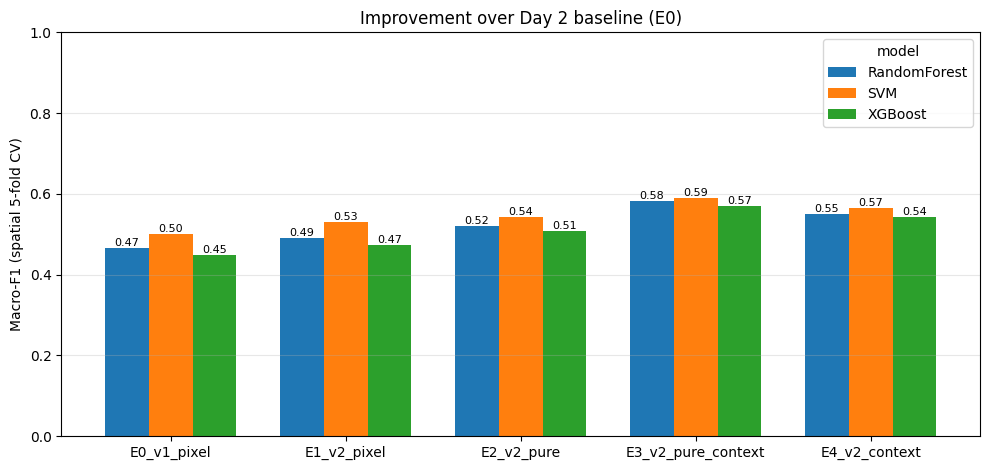

In [6]:
piv = exp.pivot(index='experiment', columns='model', values='macro_f1').loc[[e[0] for e in EXPERIMENTS]]
ax = piv.plot(kind='bar', figsize=(10, 4.8), rot=0, width=0.75)
ax.set_ylabel('Macro-F1 (spatial 5-fold CV)'); ax.set_xlabel('')
ax.set_title('Improvement over Day 2 baseline (E0)'); ax.set_ylim(0, 1); ax.grid(axis='y', alpha=0.3)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8)
plt.tight_layout(); plt.savefig(f'{RES}/improvement_macro_f1.png', dpi=150); plt.show()

### C2. SVM hyperparameter tuning (spatial CV)
Twenty C/gamma combinations are tested for the best SVM experiment using the same spatial folds.

In [7]:
from sklearn.model_selection import GridSearchCV
tune_exp = exp[exp.model == 'SVM'].sort_values('macro_f1', ascending=False).iloc[0]['experiment']
feats_t = dict((e[0], e[3]) for e in EXPERIMENTS)[tune_exp]
dft = datasets[tune_exp]
Xt, yt = dft[feats_t].values, le.transform(dft['label'])
splits_t = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(Xt, yt, dft['block']))
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(class_weight='balanced')),
                    {'svc__C': [1, 3, 10, 30, 100], 'svc__gamma': ['scale', 0.03, 0.1, 0.3]},
                    scoring='f1_macro', cv=splits_t, n_jobs=-1)
t0 = time.perf_counter(); grid.fit(Xt, yt)
TUNED = {'C': grid.best_params_['svc__C'], 'gamma': grid.best_params_['svc__gamma']}
print(f'Tuned on {tune_exp}: {TUNED}  (CV macro-F1 {grid.best_score_:.3f}, {time.perf_counter() - t0:.0f}s)')

pr = cross_val_predict(get_models()['SVM_tuned'], Xt, yt, cv=splits_t)
preds[(tune_exp, 'SVM_tuned')] = (yt, pr)
exp = pd.concat([exp, pd.DataFrame([{'experiment': tune_exp, 'model': 'SVM_tuned', 'accuracy': accuracy_score(yt, pr),
                 'macro_f1': f1_score(yt, pr, average='macro'), 'kappa': cohen_kappa_score(yt, pr),
                 'n_samples': len(yt), 'cv_time_s': None}])], ignore_index=True)
exp.to_csv(f'{RES}/experiment_results.csv', index=False)
exp.rename(columns={'experiment': 'feature_set'}).to_csv(f'{RES}/ablation_results.csv', index=False)
print(exp[exp.experiment == tune_exp][['model', 'accuracy', 'macro_f1', 'kappa']].round(3).to_string(index=False))

Tuned on E3_v2_pure_context: {'C': 1, 'gamma': 0.03}  (CV macro-F1 0.533, 176s)
       model  accuracy  macro_f1  kappa
RandomForest     0.600     0.583  0.461
         SVM     0.601     0.589  0.464
     XGBoost     0.585     0.570  0.441
   SVM_tuned     0.607     0.596  0.471


/tmp/ipykernel_1317/42877163.py:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp = pd.concat([exp, pd.DataFrame([{'experiment': tune_exp, 'model': 'SVM_tuned', 'accuracy': accuracy_score(yt, pr),


**Result:** the selected C and gamma and the `SVM_tuned` row.

## Part D – Best model: report, confusion matrix and cross-site transfer

🏆 Best: SVM_tuned · E3_v2_pure_context  macro-F1 0.596 (Day 2b best 0.565, +0.031), OA 0.607, kappa 0.471
       model  accuracy  macro_f1  kappa  cv_time_s
   SVM_tuned     0.607     0.596  0.471        NaN
         SVM     0.601     0.589  0.464        7.7
RandomForest     0.600     0.583  0.461       36.5
     XGBoost     0.585     0.570  0.441       14.4

               precision    recall  f1-score   support

        Sand      0.548     0.451     0.495      1417
      Rubble      0.620     0.583     0.601      2000
        Rock      0.661     0.756     0.706      2000
 Coral/Algae      0.570     0.593     0.581      2000

    accuracy                          0.607      7417
   macro avg      0.600     0.596     0.596      7417
weighted avg      0.604     0.607     0.604      7417



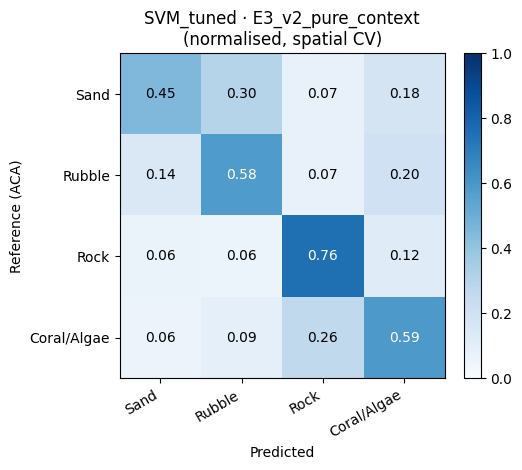

train test  accuracy  macro_f1
  HKD  PGI     0.428     0.403
  PGI  HKD     0.365     0.305


In [8]:
best = exp.sort_values('macro_f1', ascending=False).iloc[0]
BEST_EXP, BEST_MODEL = best['experiment'], best['model']
base = PREV_BEST_F1
print(f'🏆 Best: {BEST_MODEL} · {BEST_EXP}  macro-F1 {best.macro_f1:.3f} (Day 2b best {base:.3f}, '
      f'{best.macro_f1 - base:+.3f}), OA {best.accuracy:.3f}, kappa {best.kappa:.3f}')

comp = exp[exp.experiment == BEST_EXP].sort_values('macro_f1', ascending=False)[['model', 'accuracy', 'macro_f1', 'kappa', 'cv_time_s']]
comp.to_csv(f'{RES}/model_comparison.csv', index=False)
print(comp.round(3).to_string(index=False))

y_, p_ = preds[(BEST_EXP, BEST_MODEL)]
print('\n', classification_report(y_, p_, target_names=labels_txt, digits=3))
cm = confusion_matrix(y_, p_, normalize='true')
fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(labels_txt, rotation=30, ha='right')
ax.set_yticks(range(4)); ax.set_yticklabels(labels_txt)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > 0.5 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('Reference (ACA)'); ax.set_title(f'{BEST_MODEL} · {BEST_EXP}\n(normalised, spatial CV)')
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(f'{RES}/confusion_matrix.png', dpi=150); plt.show()

feats = dict((e[0], e[3]) for e in EXPERIMENTS)[BEST_EXP]
dfb = datasets[BEST_EXP]
transfer = []
for tr_, te_ in [('HKD', 'PGI'), ('PGI', 'HKD')]:
    m = get_models()[BEST_MODEL]
    a, b = dfb.site == tr_, dfb.site == te_
    m.fit(dfb.loc[a, feats].values, le.transform(dfb.loc[a, 'label']))
    pt, yt = m.predict(dfb.loc[b, feats].values), le.transform(dfb.loc[b, 'label'])
    transfer.append({'train': tr_, 'test': te_, 'accuracy': accuracy_score(yt, pt), 'macro_f1': f1_score(yt, pt, average='macro')})
pd.DataFrame(transfer).to_csv(f'{RES}/cross_site_transfer.csv', index=False)
print(pd.DataFrame(transfer).round(3).to_string(index=False))

## Part E – Final model and maps (with majority filter)

In [9]:
import sklearn, xgboost
X_all, y_all = dfb[feats].values, le.transform(dfb['label'])
final = get_models()[BEST_MODEL].fit(X_all, y_all)
use_neigh = any('_m' in f or '_s' in f for f in feats)
bundle = {'model': final, 'le': le, 'name': BEST_MODEL, 'feature_set': BEST_EXP, 'experiment': BEST_EXP,
          'features': feats, 'feature_spec': {'glint_dark_pct': 10, 'neigh_sizes': [3, 5] if use_neigh else []},
          'smooth_size': 3, 'glint_dark_pct': 10, 'class_names': CLASS_NAMES,
          'composite_version': dict((e[0], e[1]) for e in EXPERIMENTS)[BEST_EXP],
          'cv_macro_f1': float(best.macro_f1), 'cv_accuracy': float(best.accuracy),
          'versions': {'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__}}
old = f'{MOD}/best_model.joblib'
joblib.dump(bundle, f'{MOD}/best_model_v3.joblib')
if best.macro_f1 > PREV_BEST_F1 + 0.005:
    if os.path.exists(old) and not os.path.exists(f'{MOD}/best_model_v2.joblib'):
        shutil.copy(old, f'{MOD}/best_model_v2.joblib')   # keep Day 2b model
    joblib.dump(bundle, old)
    print(f'✅ IMPROVED ({PREV_BEST_F1:.3f} → {best.macro_f1:.3f}): saved as models/best_model.joblib '
          '(Day 2b model kept as best_model_v2.joblib)')
else:
    print(f'ℹ️ No clear improvement ({best.macro_f1:.3f} vs {PREV_BEST_F1:.3f}). best_model.joblib NOT changed; '
          'new model saved only as best_model_v3.joblib.')
print('Versions:', bundle['versions'], '| composite:', bundle['composite_version'])

✅ IMPROVED (0.565 → 0.596): saved as models/best_model.joblib (Day 2b model kept as best_model_v2.joblib)
Versions: {'sklearn': '1.6.1', 'xgboost': '3.4.1'} | composite: v2


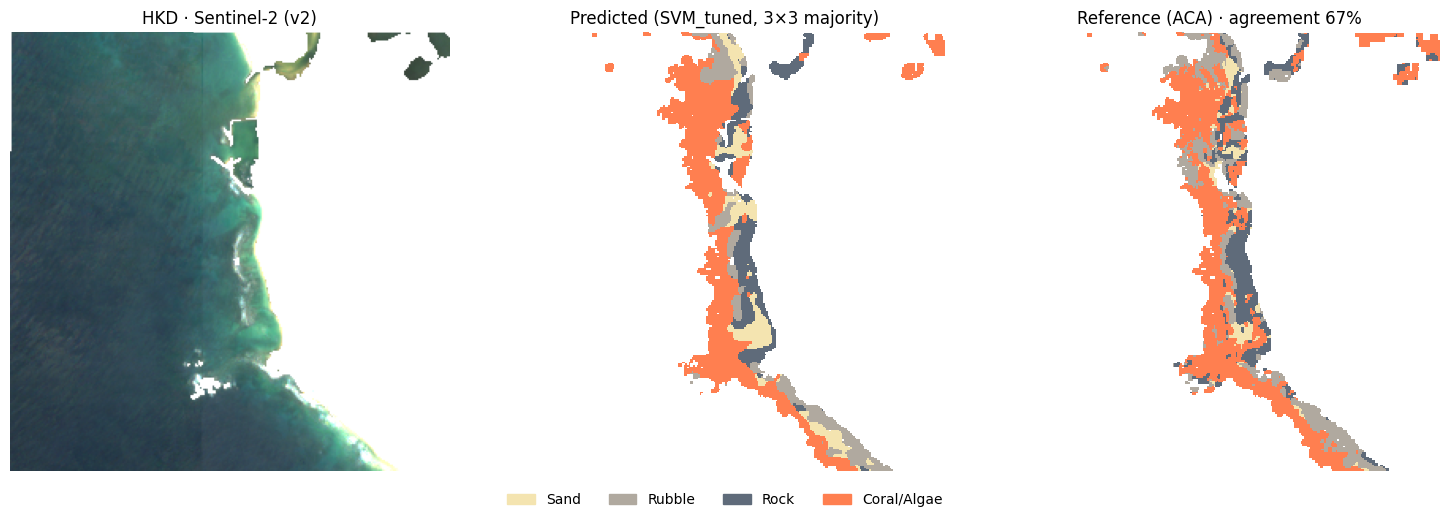

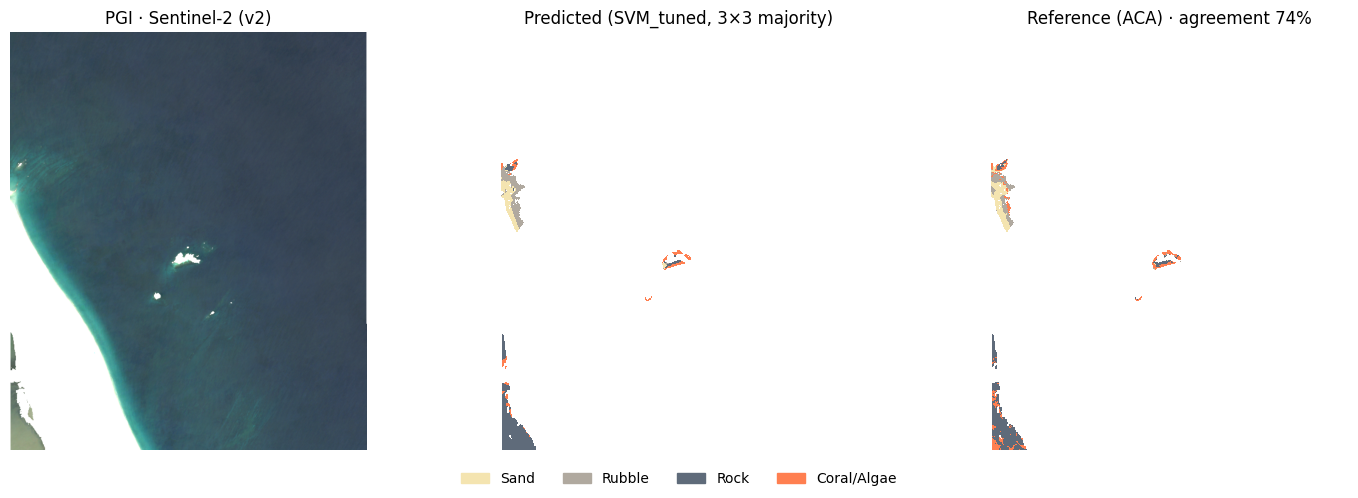

site  agreement_raw  agreement_smoothed
 HKD          0.668               0.673
 PGI          0.740               0.745
site          HKD   PGI
class                  
Coral/Algae  54.2  11.6
Rock         16.5  52.5
Rubble       16.4  19.8
Sand         13.0  16.1


In [10]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

def majority_filter(pred, valid, codes, size=3):
    counts = np.stack([uniform_filter(((pred == c) & valid).astype('float32'), size, mode='nearest') for c in codes])
    return np.where(valid, np.asarray(codes)[counts.argmax(0)], 0).astype(pred.dtype)

cmap = ListedColormap([CLASS_COLORS[c] for c in CODES])
norm = BoundaryNorm([c - 0.5 for c in CODES] + [CODES[-1] + 0.5], cmap.N)
cover_rows, agree_rows = [], []
for s in SITES:
    d = data[(bundle['composite_version'], s)]
    X = np.stack([d['f'][k] for k in feats], axis=-1)
    valid = np.isfinite(X).all(-1) & np.isin(d['lab'], CODES)
    raw = np.zeros(d['lab'].shape, np.uint8)
    raw[valid] = le.inverse_transform(final.predict(X[valid]))
    smooth = majority_filter(raw, valid, CODES, 3)
    a_raw, a_sm = (raw[valid] == d['lab'][valid]).mean(), (smooth[valid] == d['lab'][valid]).mean()
    agree_rows.append({'site': s, 'agreement_raw': a_raw, 'agreement_smoothed': a_sm})

    out = d['prof'].copy(); out.update(count=1, dtype='uint8', nodata=0)
    with rasterio.open(f'{RES}/classified_{s}.tif', 'w', **out) as dst:
        dst.write(smooth, 1)
    vals, cnt = np.unique(smooth[valid], return_counts=True)
    for v_, n in zip(vals, cnt):
        cover_rows.append({'site': s, 'class': CLASS_NAMES[int(v_)], 'pixels': int(n), 'area_ha': n / 100, 'cover_pct': 100 * n / cnt.sum()})

    rgb = np.nan_to_num(np.clip(np.stack([d['arr'][2], d['arr'][1], d['arr'][0]], -1) / 0.15, 0, 1), nan=1.0)
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(rgb); axs[0].set_title(f'{s} · Sentinel-2 ({bundle["composite_version"]})')
    axs[1].imshow(np.ma.masked_equal(smooth, 0), cmap=cmap, norm=norm, interpolation='nearest')
    axs[1].set_title(f'Predicted ({BEST_MODEL}, 3×3 majority)')
    axs[2].imshow(np.ma.masked_where(~np.isin(d['lab'], CODES), d['lab']), cmap=cmap, norm=norm, interpolation='nearest')
    axs[2].set_title(f'Reference (ACA) · agreement {a_sm:.0%}')
    for a in axs: a.axis('off')
    fig.legend(handles=[Patch(color=CLASS_COLORS[c], label=CLASS_NAMES[c]) for c in CODES], loc='lower center', ncol=4, frameon=False)
    plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.savefig(f'{RES}/map_{s}.png', dpi=150); plt.show()

pd.DataFrame(cover_rows).to_csv(f'{RES}/benthic_cover.csv', index=False)
pd.DataFrame(agree_rows).to_csv(f'{RES}/map_agreement.csv', index=False)
print(pd.DataFrame(agree_rows).round(3).to_string(index=False))
print(pd.DataFrame(cover_rows).pivot(index='class', columns='site', values='cover_pct').round(1))

**Result:** classified maps, agreement with ACA (raw vs smoothed) and benthic cover.
Map agreement includes training pixels and is optimistic; the Part C spatial-CV results are the accuracy estimate.

In [11]:
for folder in [RES, MOD]:
    print(folder)
    for fn in sorted(os.listdir(folder)):
        print(f'   {fn:32s} {os.path.getsize(os.path.join(folder, fn)) / 1024:8.1f} KB')

/content/drive/MyDrive/coral_c3/results_v3
   ablation_results.csv                  1.5 KB
   benthic_cover.csv                     0.3 KB
   classified_HKD.tif                    4.1 KB
   classified_PGI.tif                    7.2 KB
   confusion_matrix.png                 67.1 KB
   cross_site_transfer.csv               0.1 KB
   experiment_results.csv                1.5 KB
   improvement_macro_f1.png             54.4 KB
   map_HKD.png                         377.7 KB
   map_PGI.png                         466.8 KB
   map_agreement.csv                     0.1 KB
   model_comparison.csv                  0.3 KB
/content/drive/MyDrive/coral_c3/models
   best_model.joblib                   770.3 KB
   best_model_v1.joblib                140.1 KB
   best_model_v2.joblib                224.1 KB
   best_model_v3.joblib                770.3 KB


**Summary:** see Part C–E outputs (macro-F1 table, best model, transfer test, maps).
Key outputs: `improvement_macro_f1.png`, `confusion_matrix.png`, `map_HKD.png`, `map_PGI.png`.